# 01: Data Audit and Baseline (Milestone 2)

This notebook covers the data audit, preprocessing and baseline results for my CT4101 project. The question I am investigating is whether a banking client's profile and contact history can predict if they will subscribe to a term deposit, using only information that is available before a call is made.

**Dataset:** Bank Marketing (bank-full), UCI Machine Learning Repository, CC BY 4.0. Moro, S., Rita, P., & Cortez, P. (2014). https://doi.org/10.24432/C5K306

The notebook is organised as follows:
1. Setup and data loading
2. Data audit
3. Feature preparation and leakage removal
4. Evaluation design
5. Preprocessing pipeline
6. Feature check: day of the month
7. Baseline models
8. Summary and next steps

Before running it, the dataset must be downloaded once with `python src/download_data.py`.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold, cross_val_predict, cross_val_score, cross_validate, train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Make src/ importable whether the notebook is run from the repo root or notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from data import load_raw, prepare_features

RANDOM_STATE = 42
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None)

## 2. Data audit
The purpose of this audit is to understand the structure and quality of the data before making any modelling decisions.

### 2.1 Shape and variable types

In [2]:
df = load_raw()
print("Shape:", df.shape)
df.head()

Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.drop("y").tolist()
print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)
df.dtypes.to_frame("dtype").T

Numeric: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
dtype,int64,str,str,str,str,int64,str,str,str,int64,str,int64,int64,int64,int64,str,str


The dataset contains 45,211 clients and 17 columns: 7 numeric features, 9 categorical features and the target `y`.

### 2.2 Missing values
There are no `NaN` values in the file. Missing information is instead recorded as the string `"unknown"`, so I have counted both.

In [4]:
missing = pd.DataFrame({
    "NaN": df.isna().sum(),
    "'unknown'": (df == "unknown").sum(),
})
missing["'unknown' %"] = (missing["'unknown'"] / len(df) * 100).round(1)
missing[missing.sum(axis=1) > 0]

,NaN,'unknown','unknown' %
job,0,288,0.6
education,0,1857,4.1
contact,0,13020,28.8
poutcome,0,36959,81.7


Four columns contain `unknown` values, and I do not believe they should all be treated the same way.

- **poutcome** is `unknown` for 81.7% of clients. The cross-tabulation below shows that this lines up almost exactly with `pdays = -1`, meaning the client was never contacted in a previous campaign. In this column `unknown` therefore means "no previous campaign" rather than missing data.
- **contact** is `unknown` for 28.8% of clients. There is no sensible value to impute here, so I have kept `unknown` as its own category.
- **education** (4.1%) and **job** (0.6%) are also kept as their own category. Dropping these rows would throw away data, and the one-hot encoder can treat `unknown` as just another level.

In [5]:
# Check that poutcome == 'unknown' lines up with never having been contacted
pd.crosstab(df["poutcome"] == "unknown", df["pdays"] == -1,
            rownames=["poutcome unknown"], colnames=["pdays == -1"])

pdays == -1,False,True
poutcome unknown,,
False,8252,0
True,5,36954


### 2.3 Duplicates

In [6]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicates once dropped columns are removed:",
      df.drop(columns=["duration", "day"]).duplicated().sum())

Exact duplicate rows: 0
Duplicates once dropped columns are removed: 132


There are no exact duplicates in the raw data. Once `duration` and `day` are removed (see sections 3 and 6), 132 rows become identical to another row. As there is no client ID, I cannot tell whether these are the same client or simply different clients with the same profile, so I have kept them. It is worth noting that a duplicate could end up on both sides of the train/test split. With 132 rows out of 45,211 I believe the effect is minor, but I will mention it as a limitation.

### 2.4 Target distribution

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.3
yes    11.7
Name: count, dtype: float64


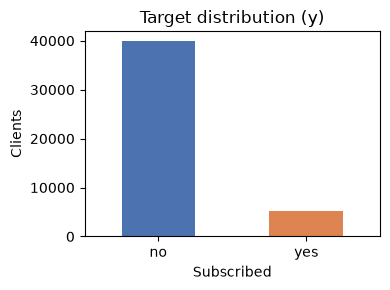

In [7]:
counts = df["y"].value_counts()
print(counts)
print((counts / len(df) * 100).round(2))

fig, ax = plt.subplots(figsize=(4, 3))
counts.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_title("Target distribution (y)")
ax.set_xlabel("Subscribed")
ax.set_ylabel("Clients")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "target_distribution.png", dpi=150)
plt.show()

Only 11.7% of clients subscribed, so the classes are heavily imbalanced. This is the reason I am not using accuracy: a model that always predicts "no" would already score 88.3% while finding no subscribers at all. PR-AUC is my main metric because it focuses on how well the model finds the positive (subscribed) class.

### 2.5 Numeric summaries and outliers

In [8]:
df[numeric_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.9,10.6,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.3,3044.8,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.8,8.3,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.2,257.5,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.8,3.1,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.2,100.1,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.6,2.3,0.0,0.0,0.0,0.0,275.0


In [9]:
def iqr_outlier_count(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.DataFrame({
    "IQR outliers": df[numeric_cols].apply(iqr_outlier_count),
    "% of rows": (df[numeric_cols].apply(iqr_outlier_count) / len(df) * 100).round(1),
})

,IQR outliers,% of rows
age,487,1.1
balance,4729,10.5
day,0,0.0
duration,3235,7.2
campaign,3064,6.8
pdays,8257,18.3
previous,8257,18.3


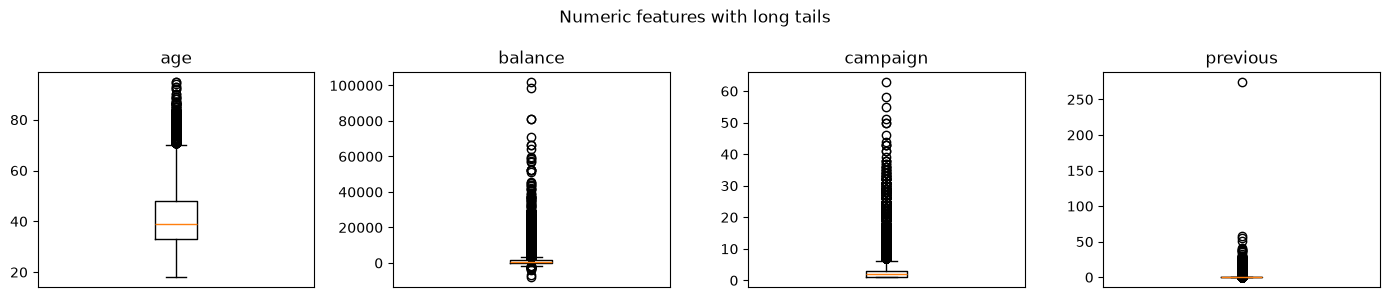

In [10]:
plot_cols = ["age", "balance", "campaign", "previous"]
fig, axes = plt.subplots(1, len(plot_cols), figsize=(14, 3))
for ax, col in zip(axes, plot_cols):
    ax.boxplot(df[col])
    ax.set_title(col)
    ax.set_xticks([])
fig.suptitle("Numeric features with long tails")
fig.tight_layout()
fig.savefig(FIG_DIR / "numeric_boxplots.png", dpi=150)
plt.show()

Three features stand out:

- **balance** is very skewed. It includes negative values (overdrafts) as low as -8,019 and a small number of very large balances up to 102,127.
- **campaign** (the number of contacts during this campaign) has a long tail, with one client called 63 times.
- **previous** is 0 for most clients, with one extreme value of 275.

The IQR rule also flags 18.3% of `pdays` and `previous`. This is because over 80% of clients were never contacted before, which squashes the interquartile range to zero. These values are not outliers in any useful sense.

These look like real but unusual values rather than recording errors, so I have kept them. Tree-based models are not affected by extreme values, and for logistic regression and kNN the numeric features are standardised. A log or robust transform for `balance` and `campaign` could be explored at Milestone 3.

### 2.6 Subscription rate by key categories
This section is not part of the required audit, but I wanted to check whether the categorical features carry any signal before modelling.

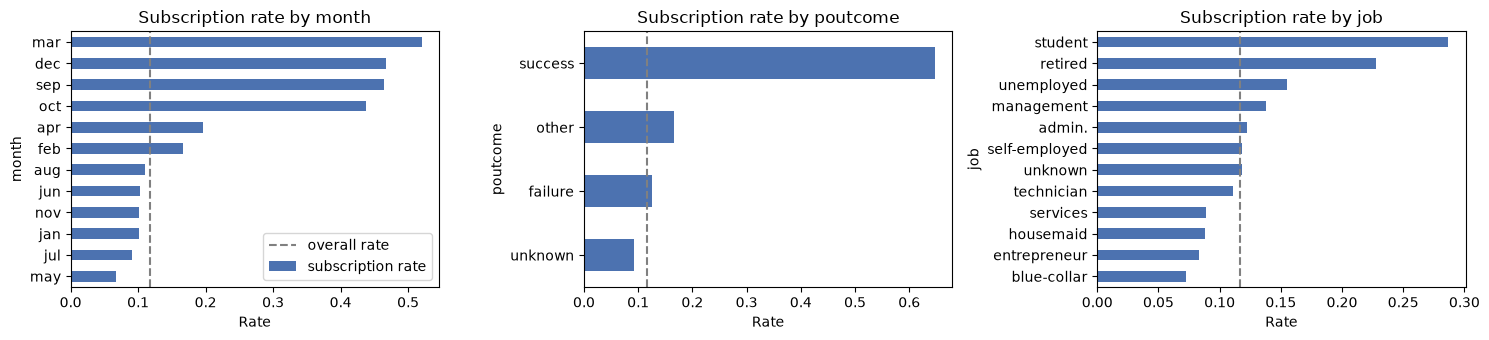

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["month", "poutcome", "job"]):
    rate = df.groupby(col)["y"].apply(lambda s: (s == "yes").mean()).sort_values()
    rate.plot.barh(ax=ax, color="#4C72B0", label="subscription rate")
    ax.axvline((df["y"] == "yes").mean(), color="grey", linestyle="--", label="overall rate")
    ax.set_title(f"Subscription rate by {col}")
    ax.set_xlabel("Rate")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "rate_by_category.png", dpi=150)
plt.show()

A successful previous campaign (`poutcome = success`) is the strongest signal, with 64.7% of those clients subscribing again. March, September, October and December also have much higher rates than average, although these were quiet months with relatively few calls, which may indicate more targeted campaigns rather than a seasonal effect. Students (28.7%) and retired clients (22.8%) subscribe most often. Age and job are therefore features where the fairness check planned in my proposal will be important.

## 3. Feature preparation and leakage removal
The `prepare_features` function in `src/data.py` applies four row-wise steps:

1. **Drops `duration`.** The length of a call is only known once the call has ended, and it strongly reveals the outcome. Keeping it would leak the answer into the model and break the "before a call is made" condition of my question.
2. **Drops `day`.** The day of the month has no plausible link to whether a client subscribes. The evidence for this decision is in section 6.
3. **Flags previous contact.** `pdays = -1` is a code for "never contacted", not a real number of days. I have added a `previously_contacted` flag and replaced the -1 with 0, so that the models do not treat -1 as a meaningful distance in time.
4. **Encodes the target.** `y` is converted to 1 (subscribed) and 0 (not subscribed).

None of these steps learn anything from the data. Each row is transformed on its own, so applying them before the train/test split does not leak information between the two sets.

In [12]:
X, y = prepare_features(df)
print(X.shape, y.shape)
X.head()

(45211, 15) (45211,)


,age,job,marital,education,default,balance,housing,loan,contact,month,campaign,pdays,previous,poutcome,previously_contacted
0,58,management,married,tertiary,no,2143,yes,no,unknown,may,1,0,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,may,1,0,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,may,1,0,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,may,1,0,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,may,1,0,0,unknown,0


## 4. Evaluation design
I have designed the evaluation so that no decision is ever made using the test set.

- **Hold-out test set:** 20% of the data is held back, stratified on `y` so that both sets keep the 11.7% positive rate. It will not be used until the final model comparison at the end of the project.
- **Cross-validation:** all model development, including tuning and feature decisions, uses stratified 5-fold cross-validation on the remaining 80%.
- **Leakage prevention:** scaling and one-hot encoding sit inside a scikit-learn `Pipeline`. In each fold they are fitted only on that fold's training portion, so the validation portion never influences the preprocessing.
- **Metrics:** PR-AUC (average precision) is the main metric. ROC-AUC and F1 at the default 0.5 threshold are also reported.

It is worth noting one limitation of this design. The records are in date order (May 2008 to November 2010), but the split is random, so the test set is not truly "future" data. I have kept the random split to match my proposal and will discuss this in the report.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " positive rate:", round(y_train.mean(), 4))
print("Test: ", X_test.shape, " positive rate:", round(y_test.mean(), 4))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (36168, 15)  positive rate: 0.117
Test:  (9043, 15)  positive rate: 0.117


## 5. Preprocessing pipeline

In [14]:
num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_features)
print("Categorical:", cat_features)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

Numeric: ['age', 'balance', 'campaign', 'pdays', 'previous', 'previously_contacted']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


The preprocessor treats the two types of feature differently:

- **Numeric features** are standardised to a mean of 0 and a standard deviation of 1. This matters for logistic regression and kNN, which are sensitive to the scale of each feature. It makes no difference to tree-based models.
- **Categorical features** are one-hot encoded, with `unknown` kept as its own level. I have set `handle_unknown="ignore"` so that the pipeline does not fail if a validation fold contains a category that was not present in its training fold.

`month` is treated as categorical rather than numeric, because there is no reason to expect the effect of month to increase steadily from January to December.

## 6. Feature check: day of the month
I originally kept `day` as a numeric feature. On review I was not convinced it should be there, so I tested it. This check uses cross-validation on the training set only, so the test set has still not been used.

In [15]:
# Re-attach day to the training rows only (train_test_split keeps the original index)
X_train_day = X_train.join(df.loc[X_train.index, "day"])

rate_by_day = y_train.groupby(X_train_day["day"]).agg(rate="mean", calls="size")
print("Distinct day-month combinations:", X_train_day.groupby(["month", "day"]).ngroups)
rate_by_day.sort_values("rate").iloc[[0, 1, 2, -3, -2, -1]].round(3)

Distinct day-month combinations: 317


,rate,calls
day,,
29,0.066,1406
20,0.069,2223
19,0.072,1404
30,0.178,1272
10,0.242,417
1,0.271,262


The subscription rate jumps between 6.6% and 27.1% depending on the day, with no clear pattern. The busiest days have the lowest rates and the quietest days have the highest, which looks to me as if it reflects how the bank scheduled its calls rather than anything about the clients.

To measure whether `day` adds predictive value, I compared PR-AUC with and without it for logistic regression and for an untuned gradient boosting model. The gradient boosting model is only used here as a quick check of whether a non-linear model can make use of `day`. It is not part of the model comparison.

In [16]:
def cv_pr_auc(model, X_):
    num = X_.select_dtypes(include="number").columns.tolist()
    cat = X_.select_dtypes(exclude="number").columns.tolist()
    prep = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ])
    scores = cross_val_score(Pipeline([("prep", prep), ("model", model)]),
                             X_, y_train, cv=cv, scoring="average_precision")
    return f"{scores.mean():.3f} ± {scores.std():.3f}"

check_models = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Gradient boosting (untuned)": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
pd.DataFrame({
    "With day": {name: cv_pr_auc(m, X_train_day) for name, m in check_models.items()},
    "Without day": {name: cv_pr_auc(m, X_train) for name, m in check_models.items()},
})

,With day,Without day
Logistic regression,0.402 ± 0.008,0.402 ± 0.008
Gradient boosting (untuned),0.444 ± 0.010,0.428 ± 0.013


For logistic regression, `day` adds nothing: PR-AUC is 0.402 with or without it. This makes sense, as treating day 30 as "more" than day 1 has no real meaning.

For gradient boosting, `day` raises PR-AUC from 0.428 to 0.444. I believe this gain comes from the model combining `day` with `month` to pick out specific calendar dates. There are only 317 day-month combinations in the training set, and because the data has no year, each one mixes calls from 2008, 2009 and 2010. The model is therefore learning which dates happened to be good campaign days, and those dates will not recur for future calls.

From this analysis I can conclude that `day` does not reflect anything about the client and that its small gain is unlikely to generalise. As such, I have dropped it. `month` carries a much larger signal and is kept, although it may also partly reflect campaign timing (see section 2.6), which I will discuss as a limitation.

## 7. Baseline models
I am using two baselines, as set out in my proposal:

1. **Majority class** (`DummyClassifier`), which always predicts "no". This sets the minimum that any learned model must beat. Its PR-AUC is equal to the positive rate.
2. **Logistic regression** with default settings and no tuning, as a simple learned baseline.

In [17]:
scoring = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "F1": "f1"}

models = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Model": name}
    for metric in scoring:
        vals = scores[f"test_{metric}"]
        row[metric] = f"{vals.mean():.3f} ± {vals.std():.3f}"
    rows.append(row)

baseline_results = pd.DataFrame(rows).set_index("Model")
baseline_results

,PR-AUC,ROC-AUC,F1
Model,,,
Majority class,0.117 ± 0.000,0.500 ± 0.000,0.000 ± 0.000
Logistic regression,0.402 ± 0.008,0.764 ± 0.003,0.277 ± 0.012


*Values are the mean ± standard deviation over the 5 cross-validation folds on the training set. The test set has not been used.*

To understand the low F1 score, I checked how many clients logistic regression labels as "yes" at the default 0.5 threshold.

In [18]:
lr_pipe = Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=1000))])
oof_proba = cross_val_predict(lr_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
print("Share predicted positive at 0.5:", round((oof_proba >= 0.5).mean(), 4))
print("Actual positive rate:          ", round(y_train.mean(), 4))

Share predicted positive at 0.5: 0.032
Actual positive rate:           0.117


## 8. Summary and next steps
The majority-class baseline scores a PR-AUC of 0.117, equal to the positive rate, and an F1 of 0, as it never predicts "yes".

Logistic regression clearly outperforms it, with a PR-AUC of 0.402 against 0.117 and a ROC-AUC of 0.764 against 0.500. Its F1 is low at 0.277, because at the default 0.5 threshold it labels only 3.2% of clients as "yes", while 11.7% of clients subscribed. The model ranks clients reasonably well, but the threshold is too strict for such an imbalanced problem.

For Milestone 3, I propose the following:
- compare kNN, a decision tree, a random forest and gradient boosting against these baselines, using the same cross-validation protocol;
- tune each model proportionately, and explore class weighting and threshold selection inside cross-validation, never on the test set;
- carry out an error analysis and the age-group fairness check from my proposal.